In [1]:
import numpy as np
import matplotlib.pyplot as plt

# Add files up one level to the path
import sys
sys.path.append("..")

import jlinops

from rsolvers import RIASGKS

# Toy problem

In [2]:
ground_truth = jlinops.piecewise_constant_1d_test_problem()
n = len(ground_truth)
np.random.seed(0)
noise_stdev = 0.1
noise_var = noise_stdev**2
A = jlinops.Gaussian1DBlurOperator(n, blur_sigma=10, mode="reflect")
#A = jlinops.IdentityOperator((n,n))
noisy_signal = A.matvec(ground_truth) + noise_stdev*np.random.normal(size=n)
grid = np.arange(n)

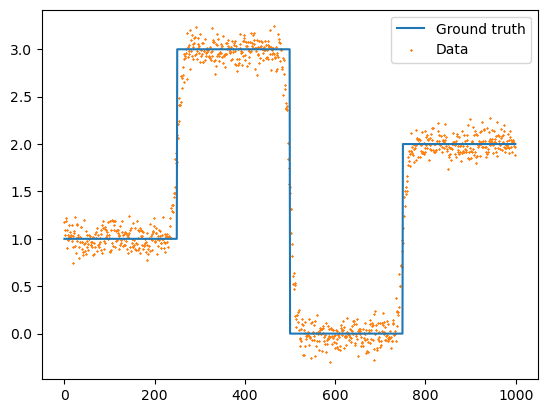

In [3]:
plt.plot(grid, ground_truth, label="Ground truth", color="C0")
plt.scatter(grid, noisy_signal, marker="x", label="Data", color="C1", alpha=1.0, s=0.5)
plt.legend()
plt.show()

# Define regularization matrix

In [4]:
Lmat, Wmat = jlinops.first_order_derivative_1d(n, boundary="none")
L = jlinops.MatrixLinearOperator(Lmat) # Cast sparse matrix R as a linear operator

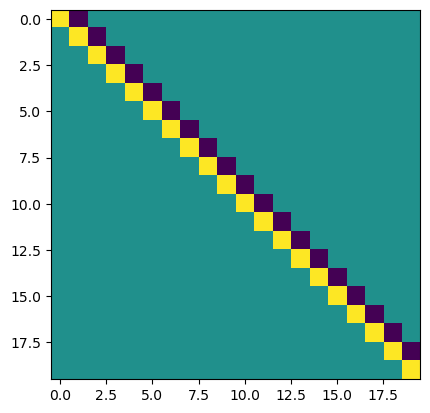

In [5]:
plt.imshow(Lmat.toarray()[:20,:20])
plt.show()

# Use solver

In [22]:
riasgks_solver = RIASGKS(A, L, noisy_signal, noise_var=noise_var)
#data = riasgks_solver.solve(n_iter=1000, init_dim=5, kmin=15, kmax=45, hyperpr_r=1, hyperpr_beta=1.5 + 1e-3, x_true=ground_truth, regparam="dp3", warmstarting=False)
data = riasgks_solver.solve(n_iter=1000, init_dim=5, kmin=15, kmax=45, hyperpr_r=-1.0, hyperpr_beta=1.0, x_true=ground_truth, regparam="dp3", warmstarting=False)

 ** On entry to DLASCL parameter number  4 had an illegal value
 ** On entry to DLASCL parameter number  4 had an illegal value
 ** On entry to DLASCL parameter number  4 had an illegal value
 ** On entry to DLASCL parameter number  4 had an illegal value
 ** On entry to DLASCL parameter number  4 had an illegal value
 ** On entry to DLASCL parameter number  4 had an illegal value
 ** On entry to DLASCL parameter number  4 had an illegal value
 ** On entry to DLASCL parameter number  4 had an illegal value
 ** On entry to DLASCL parameter number  4 had an illegal value
 ** On entry to DLASCL parameter number  4 had an illegal value
 ** On entry to DLASCL parameter number  4 had an illegal value
 ** On entry to DLASCL parameter number  4 had an illegal value
 ** On entry to DLASCL parameter number  4 had an illegal value
 ** On entry to DLASCL parameter number  4 had an illegal value


/Users/jonathanlindbloom/Github/IRLS_prec_GSBL/test_problems/../regparam_selection.py:147: RuntimeWarning: invalid value encountered in sqrt
  alpha = 2*phi_prime*np.sqrt(beta - mu)
/Users/jonathanlindbloom/Github/IRLS_prec_GSBL/test_problems/../regparam_selection.py:148: RuntimeWarning: invalid value encountered in sqrt
  gamma = phi - alpha*np.sqrt(beta - mu)
/Users/jonathanlindbloom/Github/IRLS_prec_GSBL/test_problems/../regparam_selection.py:146: RuntimeWarning: divide by zero encountered in scalar divide
  mu = beta + phi_prime/(2*phi_prime_prime)
/Users/jonathanlindbloom/Github/IRLS_prec_GSBL/test_problems/../regparam_selection.py:149: RuntimeWarning: invalid value encountered in scalar divide
  beta = mu + ((gamma/alpha)**2)
/Users/jonathanlindbloom/Github/IRLS_prec_GSBL/test_problems/../regparam_selection.py:160: RuntimeWarning: overflow encountered in scalar power
  term1 = - (2/(beta**2))*(np.linalg.norm(Lxbeta)**2)
/Users/jonathanlindbloom/Github/IRLS_prec_GSBL/test_problems

 ** On entry to DLASCL parameter number  4 had an illegal value
 ** On entry to DLASCL parameter number  4 had an illegal value
 ** On entry to DLASCL parameter number  4 had an illegal value
 ** On entry to DLASCL parameter number  4 had an illegal value
 ** On entry to DLASCL parameter number  4 had an illegal value
 ** On entry to DLASCL parameter number  4 had an illegal value
 ** On entry to DLASCL parameter number  4 had an illegal value
 ** On entry to DLASCL parameter number  4 had an illegal value
 ** On entry to DLASCL parameter number  4 had an illegal value
 ** On entry to DLASCL parameter number  4 had an illegal value
 ** On entry to DLASCL parameter number  4 had an illegal value
 ** On entry to DLASCL parameter number  4 had an illegal value
 ** On entry to DLASCL parameter number  4 had an illegal value
 ** On entry to DLASCL parameter number  4 had an illegal value
 ** On entry to DLASCL parameter number  4 had an illegal value
 ** On entry to DLASCL parameter number 

/Users/jonathanlindbloom/Github/IRLS_prec_GSBL/test_problems/../regparam_selection.py:149: RuntimeWarning: overflow encountered in scalar power
  beta = mu + ((gamma/alpha)**2)


 ** On entry to DLASCL parameter number  4 had an illegal value
 ** On entry to DLASCL parameter number  4 had an illegal value
 ** On entry to DLASCL parameter number  4 had an illegal value
 ** On entry to DLASCL parameter number  4 had an illegal value
 ** On entry to DLASCL parameter number  4 had an illegal value
 ** On entry to DLASCL parameter number  4 had an illegal value
 ** On entry to DLASCL parameter number  4 had an illegal value
 ** On entry to DLASCL parameter number  4 had an illegal value
 ** On entry to DLASCL parameter number  4 had an illegal value
 ** On entry to DLASCL parameter number  4 had an illegal value
 ** On entry to DLASCL parameter number  4 had an illegal value
 ** On entry to DLASCL parameter number  4 had an illegal value
 ** On entry to DLASCL parameter number  4 had an illegal value
 ** On entry to DLASCL parameter number  4 had an illegal value
 ** On entry to DLASCL parameter number  4 had an illegal value
 ** On entry to DLASCL parameter number 

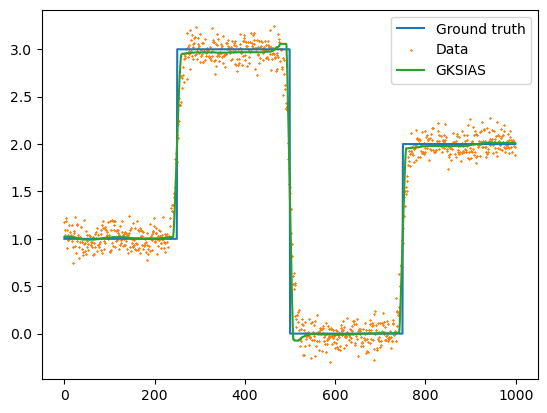

In [24]:
plt.plot(grid, ground_truth, label="Ground truth", color="C0")
plt.scatter(grid, noisy_signal, marker="x", label="Data", color="C1", alpha=1.0, s=0.5)
plt.plot(grid, data["x"], label="GKSIAS", color="C2")
plt.legend()
plt.show()

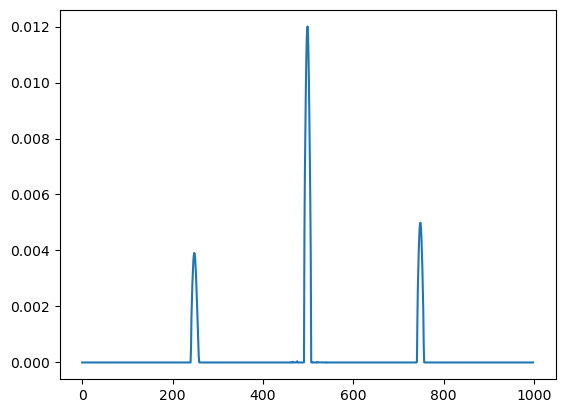

In [25]:
plt.plot(data["theta"])
plt.show()

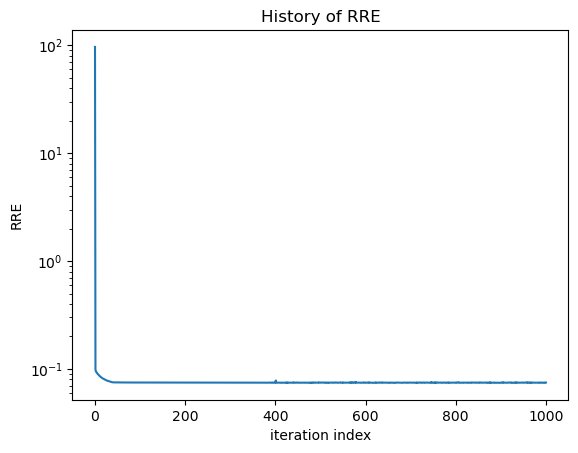

In [26]:
plt.plot(data["rre_history"])
plt.yscale("log")
plt.title("History of RRE")
plt.ylabel("RRE")
plt.xlabel("iteration index")
plt.show()

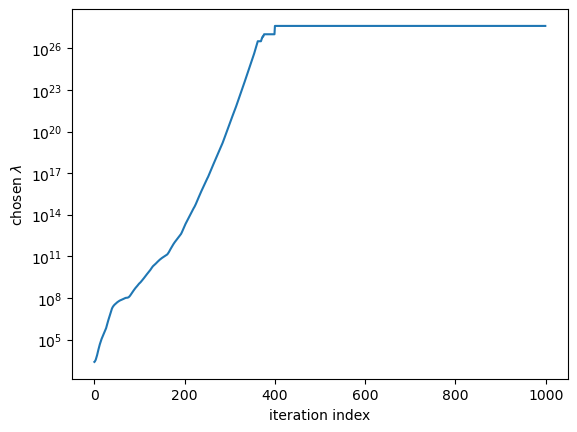

In [27]:
plt.plot(data["lambda_history"])
plt.yscale("log")
plt.xlabel("iteration index")
plt.ylabel("chosen $\\lambda$")
plt.show()

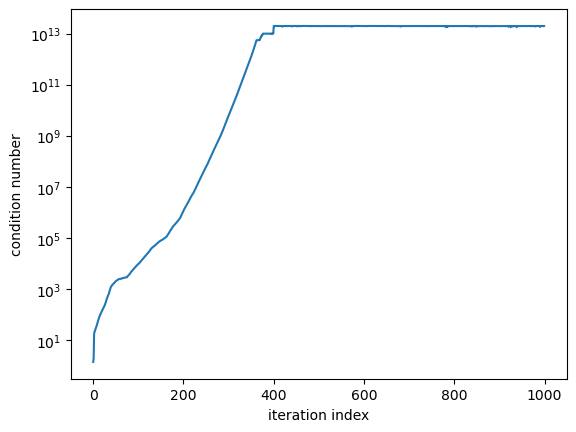

In [28]:
plt.plot(data["cond_ests"])
plt.yscale("log")
plt.xlabel("iteration index")
plt.ylabel("condition number")
plt.show()

IndexError: index 15 is out of bounds for axis 1 with size 15

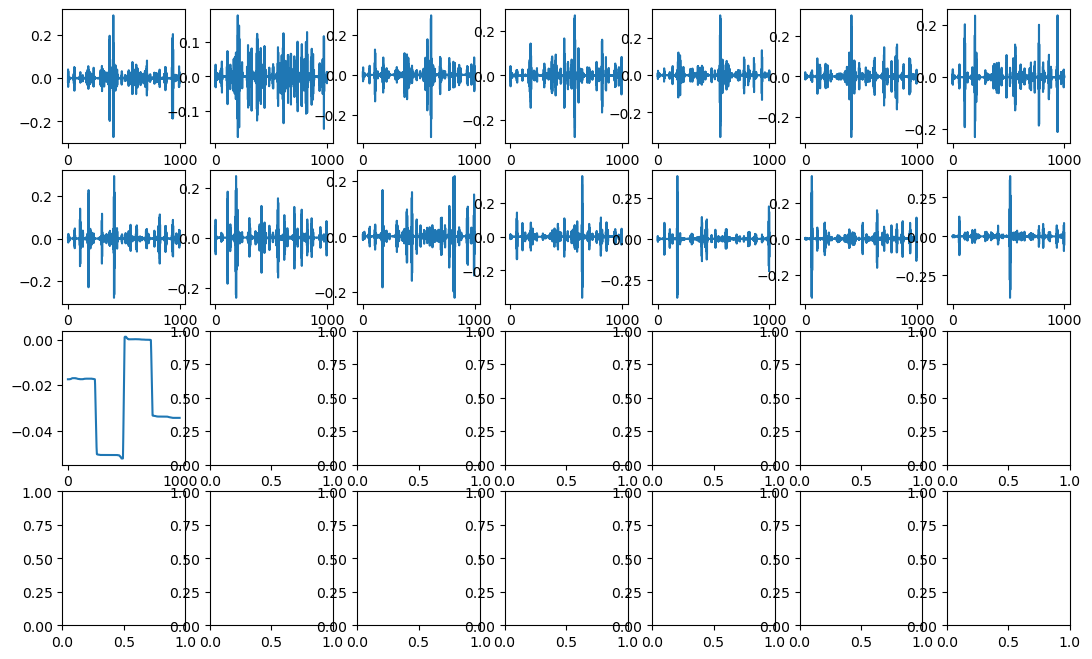

In [29]:
fig, axs = plt.subplots(4,7,figsize=(13,8))

for j, ax in enumerate(axs.reshape(-1)):
    ax.plot(data["V"][:,j])